# Triton Requirements Guide: how it compares

Eleven UCSD requirement questions, answered by NotebookLM, by our app (Gemini API + our own catalog index), and (to be filled in) by Google AI Studio.

**Rubric** (scored against the catalog pages, not against each other)

| Score | Meaning |
|---|---|
| 2 | Correct and complete |
| 1 | Partial or missing a piece |
| 0 | Wrong, or says "not covered" when the catalog pages do cover it |

Plus: does the citation point to the right page (yes / no)? The scores are in `eval/grades.json` so anyone can check or change them.

In [1]:
import json, re
from pathlib import Path
from collections import Counter
import sys
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

root = Path("..") if Path("../eval").exists() else Path(".")
sys.path.insert(0, str(root))
questions = json.loads((root / "eval/questions.json").read_text())
theirs = json.loads((root / "eval/notebooklm_answers.json").read_text())
ours = json.loads((root / "eval/our_answers.json").read_text())
grades = json.loads((root / "eval/grades.json").read_text())
studio = json.loads((root / "eval/aistudio_answers.json").read_text())
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})
NAVY, GREY, GOLD = "#182B49", "#9AA3B2", "#C69214"

# Our citation check is automatic: did the answer cite one of the pages that should be cited?
def our_citation(i):
    accepted = questions[i]["accept_url_substrings"]
    return any(any(a in url for a in accepted) for url in ours[i]["sources"])
for i, g in enumerate(grades["ours"]):
    g["citation"] = our_citation(i)

## 1. Scores per question

,question,NotebookLM,Ours (live app),"AI Studio, question only","AI Studio, our prompt pasted in"
1,How many upper-division electives do I need fo...,0,1,2,2
2,What are the Warren College writing requirements?,1,2,2,2
3,What is the Revelle College Humanities sequence?,1,2,2,2
4,What are the general education requirements at...,2,2,2,2
5,What are the required courses for the bioengin...,0,2,2,2
6,What does CSE 150A cover?,0,2,2,2
7,How many units do I need to graduate from UCSD?,2,2,2,2
8,What math courses does a mechanical engineerin...,1,2,2,2
9,I took CSE 12 and 21. What should I take next ...,1,2,2,2
10,What are the requirements for the bioinformati...,1,2,1,2


Total out of 22:
NotebookLM                         10
Ours (live app)                    21
AI Studio, question only           21
AI Studio, our prompt pasted in    22


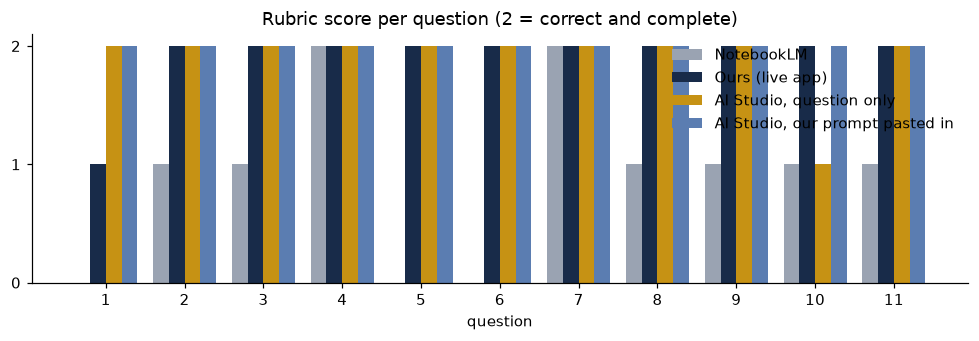

In [2]:
rows = []
for i, q in enumerate(questions):
    row = {"question": q["question"][:62],
           "NotebookLM": grades["notebooklm"][i]["score"],
           "Ours (live app)": grades["ours"][i]["score"]}
    for key, name in (("bare", "AI Studio, question only"), ("pasted", "AI Studio, our prompt pasted in")):
        if studio[key][i]["score"] is not None:
            row[name] = studio[key][i]["score"]
    rows.append(row)
scores = pd.DataFrame(rows); scores.index += 1
display(scores)
tools = [c for c in scores.columns if c != "question"]
print(f"Total out of {2 * len(scores)}:")
print(scores[tools].sum().to_string())

fig, ax = plt.subplots(figsize=(9, 3.2))
x = range(len(scores))
width = 0.8 / len(tools)
for k, (tool, color) in enumerate(zip(tools, [GREY, NAVY, GOLD, "#5B7DB1"])):
    ax.bar([i - 0.4 + width * (k + 0.5) for i in x], scores[tool], width, label=tool, color=color)
ax.set_xticks(list(x)); ax.set_xticklabels(scores.index); ax.set_xlabel("question"); ax.set_yticks([0, 1, 2])
ax.set_title("Rubric score per question (2 = correct and complete)"); ax.legend(frameon=False)
plt.tight_layout()

## 2. How each tool fails

,NotebookLM,Ours (live app),"AI Studio, question only","AI Studio, our prompt pasted in"
no problem,2,10,10,11
partial answer,6,1,1,0
said 'not covered' but the pages cover it,3,0,0,0


Citation points to the right page:
               NotebookLM  Ours (live app)  AI Studio, question only  \
no                      3                0                         0   
not checkable           8                0                        11   
yes                     0               11                         0   

               AI Studio, our prompt pasted in  
no                                           0  
not checkable                                0  
yes                                         11  
NotebookLM answers carry citation numbers but not page names, so 'not checkable' means the pasted answer does not say which page was used.


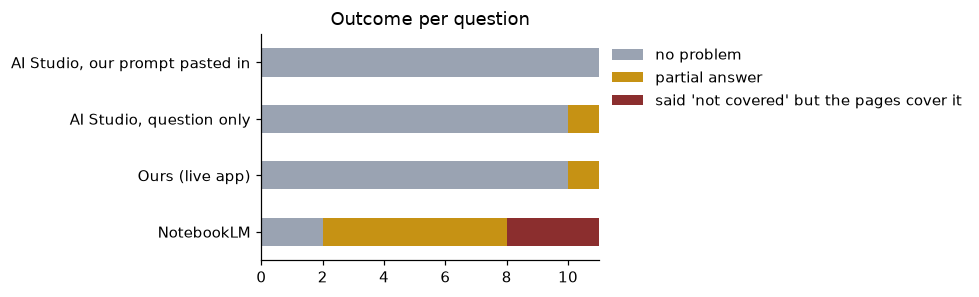

In [3]:
labels = {"none": "no problem", "incomplete": "partial answer", "not_covered": "said 'not covered' but the pages cover it"}
outcomes = {"NotebookLM": Counter(g["failure"] for g in grades["notebooklm"]),
            "Ours (live app)": Counter(g["failure"] for g in grades["ours"])}
for key, name in (("bare", "AI Studio, question only"), ("pasted", "AI Studio, our prompt pasted in")):
    if studio[key][0]["score"] is not None:
        outcomes[name] = Counter(x["failure"] for x in studio[key])
counts = pd.DataFrame(outcomes).fillna(0).astype(int).reindex(list(labels)).rename(index=labels)
display(counts)
counts.T.plot.barh(stacked=True, figsize=(9, 2.8), color=[GREY, GOLD, "#8B2E2E"])
plt.title("Outcome per question"); plt.legend(frameon=False, bbox_to_anchor=(1, 1)); plt.tight_layout()

cite_cols = {"NotebookLM": [{True: "yes", False: "no", None: "not checkable"}[g["citation"]] for g in grades["notebooklm"]],
             "Ours (live app)": ["yes" if g["citation"] else "no" for g in grades["ours"]]}
for key, name in (("bare", "AI Studio, question only"), ("pasted", "AI Studio, our prompt pasted in")):
    if studio[key][0]["score"] is not None:
        cite_cols[name] = [{True: "yes", False: "no", None: "not checkable"}[x["citation"]] for x in studio[key]]
cites = pd.DataFrame(cite_cols, index=scores.index)
print("Citation points to the right page:")
print(cites.apply(pd.Series.value_counts).fillna(0).astype(int))
print("NotebookLM answers carry citation numbers but not page names, so 'not checkable' means the pasted answer does not say which page was used.")

Reading this: NotebookLM's wrong answers are almost all the same kind, "your sources don't include this". That is a **data** problem. The answer exists in the catalog; the page was not in its sources, or it could not find the line. The next section looks at the data our app searches.

## 3. The data behind our answers

58 catalog pages  ->  1296 searchable chunks  ->  2021 courses with parsed prerequisites


,pages,chunks
major / department program,29,578
university-wide,5,149
course descriptions,17,433
college requirements,7,136


45% of courses have prerequisites the code can check (ready / missing). The rest are passed to the model as written.


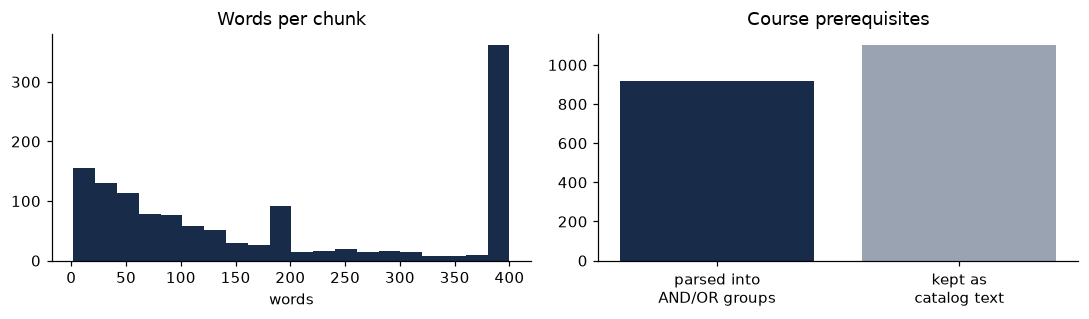

In [4]:
chunks = json.loads((root / "data/index.json").read_text())
courses = json.loads((root / "data/courses.json").read_text())
import courses as course_lookup

def kind(url):
    if "/curric/" in url: return "major / department program"
    if "/courses/" in url: return "course descriptions"
    if "/colleges/" in url: return "college requirements"
    return "university-wide"
pages = {c["url"]: kind(c["url"]) for c in chunks}
by_kind = Counter(pages.values())
print(f"{len(pages)} catalog pages  ->  {len(chunks)} searchable chunks  ->  {len(courses)} courses with parsed prerequisites")
display(pd.DataFrame({"pages": by_kind, "chunks": Counter(kind(c['url']) for c in chunks)}).fillna(0).astype(int))

words = [len(c["text"].split()) for c in chunks]
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
axes[0].hist(words, bins=20, color=NAVY); axes[0].set_title("Words per chunk"); axes[0].set_xlabel("words")
structured = sum(1 for c in courses if course_lookup.prereq_groups(c) is not None)
axes[1].bar(["parsed into\nAND/OR groups", "kept as\ncatalog text"], [structured, len(courses) - structured], color=[NAVY, GREY])
axes[1].set_title("Course prerequisites")
plt.tight_layout()
print(f"{structured / len(courses):.0%} of courses have prerequisites the code can check (ready / missing). The rest are passed to the model as written.")

In [5]:
# Did retrieval put the right page in front of the model? (same check as eval/run_eval.py, from the saved run)
hit = [our_citation(i) for i in range(len(questions))]
print(f"Right page cited: {sum(hit)}/{len(hit)}")
times = [a["seconds"] for a in ours]
print(f"Answer time: median {sorted(times)[len(times)//2]} s, slowest {max(times)} s (includes retrieval)")

Right page cited: 11/11
Answer time: median 1.3 s, slowest 3.9 s (includes retrieval)


**Why the data is better than uploading the same links to a notebook tool**

- **Whole pages are indexed, not summaries.** Program pages are split by heading and each chunk starts with the program name ("BS Artificial Intelligence Program / 2. Upper-Division Requirements"), so a question about one major does not retrieve another major's rules.
- **A separate course table.** Every course has its title, units and prerequisites parsed into groups ("any one of CSE 8B, CSE 11"). That is what lets the app say CSE 12 means CSE 8B or 11 is done, and which courses are Ready or Missing. A plain document search cannot do this.
- **Retrieval is ours to tune.** "What should I take next?" searches lower-division, upper-division and elective sections separately; a named course goes to the course table first. We can test each fix with the eval, which a closed notebook tool does not allow.
- **The model is told what it may and may not do** (answer only from the sources, cite, say when something is not covered, no major-restriction noise, no courses from unrelated departments).

## 4. Google AI Studio

Two arms:

- **Question only**: no data from us. AI Studio was told to find and search for the answers itself.
- **Our prompt pasted in**: the same rules and retrieved sources the app uses. This tests the *model*, not our data.

Citations in the question-only paste were stripped, so they cannot be checked. The model and search tools used were not recorded.

In [6]:
bare, pasted = studio["bare"], studio["pasted"]
rows = pd.DataFrame({
    "words, ours": [len(x["answer"].split()) for x in ours],
    "words, AI Studio (question only)": [len(x["answer"].split()) for x in bare],
    "words, AI Studio (pasted)": [len(x["answer"].split()) for x in pasted],
    "time, ours (s)": [x["seconds"] for x in ours]}, index=scores.index)
display(rows)
print("Where the question-only arm lost points:")
for i, x in enumerate(bare, 1):
    if x["score"] < 2:
        print(f"  {i}. {x['note']}")

,"words, ours","words, AI Studio (question only)","words, AI Studio (pasted)","time, ours (s)"
1,78,94,134,3.9
2,170,90,124,1.3
3,79,77,120,1.0
4,190,145,137,1.4
5,229,93,167,1.6
6,58,63,78,1.1
7,101,49,115,3.2
8,38,35,79,1.0
9,116,190,275,1.2
10,416,204,239,2.2


Where the question-only arm lost points:
  10. Treats PHYS 2A-C, CSE 11 or 8A-B and CSE 100/101 as shared by every track, which is wrong for the CSE specialization (PHYS 2A only). Biology-track details not checkable against the indexed pages.


What this shows, plainly:

- **Against NotebookLM, our approach wins clearly** (21 to 22 out of 22 against 10). NotebookLM's losses are mostly "your sources don't include this", which is a data problem.
- **Against AI Studio with search, there is no accuracy gap on these 11 questions.** Question only scored 21, the same as our live app, and our rules and sources pasted into AI Studio scored 22. A search-enabled model finds the same catalog pages. Do not claim otherwise.
- **The one visible slip in the question-only arm** is question 10: it merges the three bioinformatics tracks and lists requirements (PHYS 2A-C, for example) that the CSE specialization does not have. Its Sixth College area names also differ from the catalog we indexed, which could be a different catalog year. We cannot tell which is current.
- **What the project adds beyond raw accuracy** (these are properties, not scores): every claim carries a citation that opens the exact catalog page; the app says "not covered" instead of guessing; it is limited to one catalog snapshot that we can test and re-run; answers take about 1.4 s; no student question is stored; and the free quota is ours to manage. Prerequisite reasoning (CSE 12 means CSE 8B or 11) is done by code and can be audited, but the question-only arm also got question 9 right.
- **Where AI Studio beat the live app:** question 1, where the larger model itemised the 4 ethics units that the live Flash-Lite model misplaced.

## 5. Supporting check: required facts

In [7]:
def found(answer, patterns):
    return sum(bool(re.search(p, answer)) for p in patterns)
facts = pd.DataFrame([{"facts needed": len(q["must_include"]),
                       "NotebookLM": found(t["answer"], q["must_include"]),
                       "Ours": found(o["answer"], q["must_include"])}
                      for q, t, o in zip(questions, theirs, ours)])
facts.index += 1
print(facts.sum().to_string())
print("Keyword matching, so it is only a cross-check of the hand scores above.")

facts needed    30
NotebookLM      13
Ours            30
Keyword matching, so it is only a cross-check of the hand scores above.


## 6. Answers side by side

In [8]:
for i, (q, t, o) in enumerate(zip(questions, theirs, ours), 1):
    gt, go = grades["notebooklm"][i - 1], grades["ours"][i - 1]
    pages = ", ".join(sorted(set(s.replace("https://catalog.ucsd.edu/", "") for s in o["sources"]))) or "none cited"
    display(Markdown(f"### {i}. {q['question']}\n\n**NotebookLM** (score {gt['score']}): {gt['note']}\n\n{t['answer']}\n\n**Ours** (score {go['score']}): {go['note']}\n\n{o['answer']}\n\n_Our cited pages: {pages}_"))

### 1. How many upper-division electives do I need for the BS in Artificial Intelligence?

**NotebookLM** (score 0): Says the elective breakdown is not detailed, but the AI program page states 44 elective units.

The **BS in Artificial Intelligence** requires **124 total units** for major requirements, with **60 units** dedicated to lower-division coursework. The specific upper-division elective unit breakdown is not fully detailed in the provided catalog excerpt.

**Ours** (score 1): Totals right (64 = 20 core + 44 elective) but the 44 is broken into 12 AI + 28 CSE and the 4-unit ethics item is wrongly placed in the core.

For the BS in Artificial Intelligence, students must complete sixty-four upper-division units [1]. This total includes twenty units of core courses and forty-four units of elective courses [1]. 

The elective courses are further divided into the following parts: four units for the ethics requirement, which can be CSE 194, PHIL 174, or POLI 121D [1]; twelve units of AI electives [1]; and twenty-eight units of CSE electives [1].

Please check with your academic advisor to confirm your requirements.

_Our cited pages: curric/CSE-ug.html_

### 2. What are the Warren College writing requirements?

**NotebookLM** (score 1): Correct (two-course writing sequence, two ethics courses) but gives no course codes.

**Earl Warren College** requires a **two-quarter writing sequence** (**WRITING—2**) through the Warren College Writing Program, which focuses on written argumentation based on primary and secondary sources. Students must also complete **two courses in Ethics and Society**.

**Ours** (score 2): WCWP 10A-B, WARR 11A-B, PHIL/POLI 27-28, transfer path.

For first-year students entering Warren College, the writing requirement follows completion of the UC Entry Level Writing Requirement and consists of a two-course sequence in Warren Writing for a letter grade (WCWP 10A-B) [1], [2]. Alternatively, first-year students who meet the Warren College Honors Society requirements and are invited to participate may enroll in WARR 11A-B to fulfill this requirement [3]. 

Following the writing program, first-year students must take two core courses in ethics and society for a letter grade, which are PHIL 27 or POLI 27, and PHIL 28 or POLI 28 [2], [5]. PHIL 27 or POLI 27 must be taken before PHIL 28 or POLI 28 [5].

Transfer students who have completed their lower-division general education requirements and/or a transfer agreement take Academic Writing (WCWP 100) plus one upper-division course outside of their major discipline [4]. All other transfer students must complete WCWP 100 and two programs of concentration or area studies if they are majoring in engineering [4].

Please confirm these details with your academic advisor.

_Our cited pages: curric/WARR.html, undergraduate/colleges/earl-warren-college/index.html_

### 3. What is the Revelle College Humanities sequence?

**NotebookLM** (score 1): Correct (5-course humanities sequence) but no HUM 1-5 detail or prerequisites.

**Revelle College** requires a **5-course core Humanities sequence** (**HUMANITIES—5**), which includes intensive instruction in university-level writing.

**Ours** (score 2): HUM 1-5 with units and ordering.

The Revelle College humanities requirement is satisfied by completing a five-quarter interdisciplinary sequence of courses in history, literature, and philosophy, known as HUM 1 through HUM 5 [1, 2]. 

The sequence consists of five courses total: two six-unit courses with intensive instruction in university-level writing (HUM 1 and HUM 2) and three four-unit courses with less intensive writing instruction (HUM 3, HUM 4, and HUM 5) [1, 5]. 

Please check with your academic advisor to confirm these details [1].

_Our cited pages: curric/HUM.html, undergraduate/colleges/revelle-college/index.html_

### 4. What are the general education requirements at Sixth College?

**NotebookLM** (score 2): Covers CAT, IT fluency, modes of inquiry, exploring data, art making, practicum.

Sixth College GE requirements: Culture, Art, and Technology (CAT): 4 courses (a 3-quarter lower-division core writing sequence plus CAT 125 upper-division writing). Information Technology Fluency: 1 computing course. Modes of Inquiry: 7 courses (2 Social Sciences, 2 Humanities, 2 Natural Sciences, 1 Math/Logic). Exploring Data: 1 statistical methods course. Art Making: 2 courses. Practicum: 1 capstone project course.

**Ours** (score 2): All six areas plus experiential learning and CAT 125.

To graduate from Sixth College, students must satisfy the general education requirements across several areas [3]. 

The requirements include Culture, Art, and Technology, which is a core sequence of three courses, CAT 1, CAT 2, and CAT 3, including two six-unit quarters of intensive instruction in university-level writing [1]. 

Students need one course in Information Technology Fluency, which may be satisfied with courses from a variety of departments [1]. 

There is a Modes of Inquiry requirement consisting of seven total courses: two courses in social sciences, two courses in humanities, two courses in natural sciences, and one course in math/logic, with options available for science and nonscience majors [1]. 

For Exploring Data, students need one course in statistical methods, with options available for science and nonscience majors [1]. 

The Art Making requirement is two courses in literature, music, theatre and dance, or visual arts [1]. 

Upper-division students must complete a four-unit experiential learning course [1]. 

Finally, students must take a four-unit upper-division writing course, which is CAT 125 or the remote version CAT 125R, to study public rhetoric and practical communication [1]. 

Please confirm all requirements with your academic advisor.

_Our cited pages: undergraduate/colleges/sixth-college/index.html_

### 5. What are the required courses for the bioengineering major?

**NotebookLM** (score 0): Says the bioengineering page is missing from its sources.

Your sources note that **Bioengineering** is part of the Jacobs School of Engineering and detail general lower-division engineering preparation (including **MATH 18, MATH 20A–D, PHYS 2A–C**, and **10 units of General Chemistry with lab**). However, the specific Bioengineering department catalog page (`curric/BENG-ug`) is missing from your uploaded sources.

**Ours** (score 2): Year-by-year required list from the bioengineering page.

The required courses for the bioengineering (BS) major are organized by year in the curriculum. 

For the first year, the required courses are MATH 20A, MATH 20B, and MATH 20C [1]. Also required are CHEM 6A and CHEM 6B [1]. Additional requirements include BILD 1, PHYS 2A, and PHYS 2B/2BL [1]. Students also take BENG 1 and HSS courses [1]. 

For the sophomore year, the required courses are MATH 18, MATH 20D, and MATH 20E [1]. Other required courses are CHEM 7L, MAE 40, MAE 3, PHYS 2C/2CL, BENG 140A, BENG 100, MAE 8, and BENG 140B, along with HSS courses [1]. 

For the junior year, the required courses are BENG 110, BENG 112A, BENG 112B, BENG 152, BENG 186B, BENG 172, BENG 103B, MAE 107, BENG 130, and BENG 187A, along with HSS courses [1]. 

For the senior year, the required courses are BENG 187B, BENG 187C, BENG 125, BENG 188A, BENG 188B, BENG 186A, BENG 187D, MAE 150, BENG 122A, technical electives selected from a departmental approved list, and HSS courses [1]. 

To graduate, students must maintain an overall GPA of at least 2.0, obtain at least a C- grade in each course required for the major, and take all required courses for a letter grade [5]. Technical electives require departmental approval prior to taking the course [5]. 

Please confirm these requirements with your academic advisor [1].

_Our cited pages: curric/BENG-ug.html_

### 6. What does CSE 150A cover?

**NotebookLM** (score 0): Says the course description is not in its sources.

**CSE 150A** is listed in your sources as an upper-division core option for Data Science majors (paired with DSC 140A). However, the individual course description detailing what the course covers is not included in the provided catalog excerpts.

**Ours** (score 2): Description and topics from the course page.

CSE 150A covers probabilistic models at the heart of modern artificial intelligence, specifically covering probabilistic methods for reasoning and decision-making under uncertainty, inference and learning in Bayesian networks, prediction and planning in Markov decision processes, and applications to intelligent systems, speech and natural language processing, information retrieval, and robotics [1].

Please confirm these details with your academic advisor.

_Our cited pages: courses/CSE.html_

### 7. How many units do I need to graduate from UCSD?

**NotebookLM** (score 2): 180 units, 60 upper-division.

A minimum of **180 cumulative units** is required to graduate from UC San Diego, with at least **60 units at the upper-division level**.

**Ours** (score 2): 180 units, 60 upper-division.

Each college at UCSD must set a minimum requirement for a bachelor's degree equivalent to a total of at least 180 units [1]. This total includes its parts: not less than 60 units at the upper-division level [1]. 

Specifically, a bachelor of arts or bachelor of science degree at Revelle College, Earl Warren College, Seventh College, and Thurgood Marshall College requires a minimum total of 180 units, with at least 60 units of those taken at the upper-division level [2, 5, 6, 7, 8]. 

Please check with your academic advisor to confirm the exact requirements for your specific college and major.

_Our cited pages: undergraduate/colleges/earl-warren-college/index.html, undergraduate/degree-requirements/index.html, undergraduate/graduation-requirements/index.html_

### 8. What math courses does a mechanical engineering major need?

**NotebookLM** (score 1): Gives generic engineering math and says the mechanical engineering page is missing; no MATH 20E.

Lower-division math preparation required for engineering majors across the Jacobs School includes **Linear Algebra (MATH 18), Calculus I (MATH 20A), Calculus II (MATH 20B), Calculus and Analytic Geometry (MATH 20C)**, and **Differential Equations (MATH 20D)**. The dedicated Mechanical Engineering catalog page (`curric/MAE-ug`) is not in your uploaded sources.

**Ours** (score 2): MATH 18, 20A-E from the mechanical engineering page.

Based on the recommended course sequence for the mechanical engineering major, students take MATH 20A, MATH 20B, MATH 20C, MATH 18, MATH 20D, and MATH 20E [1]. 

Please confirm with your academic advisor to verify all requirements [1].

_Our cited pages: curric/MAE-ug.html_

### 9. I took CSE 12 and 21. What should I take next as an AI major?

**NotebookLM** (score 1): Right courses but a flat list: CSE 30 and 55 are listed as next with no sense of which are blocked by prerequisites.

For a **BS in Artificial Intelligence**, lower-division CSE requirements include CSE 8B/11, CSE 12, CSE 15L or 29, CSE 20, CSE 21, and CSE 30, along with AI-specific courses **CSE 25** and **CSE 55**. Having completed CSE 12 and CSE 21, your remaining lower-division CSE/AI requirements to take next are **CSE 30, CSE 15L or CSE 29, CSE 25**, and **CSE 55**.

**Ours** (score 2): Counts CSE 8B/11 and CSE 20 as done, separates Ready courses from blocked ones. Weak spot: electives are vague.

Since you finished CSE 12 and CSE 21, I counted CSE 8B or CSE 11 and CSE 20 or MATH 15A as done. 

Here are the required courses marked Ready that you should take next: CSE 15L (2 units) [1, 7, 10], CSE 29 (4 units) [1, 2, 10], and CSE 25 (4 units) [1, 2, 10]. 

Required courses that are Missing prerequisites and should be taken as later steps include CSE 30 (4 units) [1, 2, 10], CSE 55 (8 units) [1, 10], and CSE 103 (4 units) [1, 10]. 

For electives, you can explore introductory options such as COGS 18 or ECE 15 [1]. 

Please confirm your course plan with an academic advisor [10].

_Our cited pages: courses/CSE.html, curric/CSE-ug.html_

### 10. What are the requirements for the bioinformatics major?

**NotebookLM** (score 1): Lower-division only; no upper-division requirements or bioinformatics series.

The **BS Computer Science with Specialization in Bioinformatics** requires **128 total major units**. Lower-division requirements (62–64 units) include: CSE: CSE 8B/11, CSE 12, CSE 15L or 29, CSE 21, CSE 30 (18–20 units), plus 2 units of lower-division CSE electives. Mathematics: MATH 20A, MATH 20B, MATH 20C (or MATH 31BH), and MATH 18 (or MATH 31AH) (16 units). Chemistry: CHEM 6A–B (8 units) and Organic Chemistry CHEM 40A or 41A (4 units). Biology: BILD 1, BILD 3, and BILD 4 (10 units). Physics: PHYS 2A (4 units).

**Ours** (score 2): Lower- and upper-division requirements and the bioinformatics series. Not every unit count was checked by hand.

Students wishing to study bioinformatics may choose from majors offered by the School of Biological Sciences, the Department of Bioengineering, and the Department of Computer Science and Engineering [1]. Each participating unit has its own requirements and emphases [1, 5].

For the BS computer science with a specialization in bioinformatics program, the requirements total 128 units, not including general education [4]. This includes sixty-two or sixty-four lower-division units and sixty-four upper-division units [7, 8]. The lower-division requirements are:
Computer science and engineering: eighteen or twenty units, comprising CSE 8B or 11, CSE 12, CSE 15L or CSE 29, CSE 21, and CSE 30 [7].
Computer science and engineering: a minimum of two units chosen from CSE 3, CSE 4GS, CSE 6R, CSE 6GS, CSE 8A, CSE 25, CSE 42, CSE 86, CSE 89, CSE 90, CSE 91, CSE 95, CSE 99, CSE 180, CSE 180R, MAE 8, MAE 9, COGS 9, COGS 10, COGS 18, ECE 15, ENG 10, ENG 15, NANO 15, CENG 15, or any CSE upper-division course not used to fulfill other degree requirements [7].
Mathematics: sixteen units, comprising MATH 20A, MATH 20B, MATH 20C or MATH 31BH, and MATH 18 or MATH 31AH [7].
Chemistry: eight units, comprising CHEM 6A-B [7].
Organic chemistry: four units, comprising CHEM 40A or CHEM 41A [7].
Biology: ten units, comprising BILD 1, BILD 3, and BILD 4 [7].
Physics: four units, comprising PHYS 2A [7].

The upper-division requirements for the computer science specialization total sixty-four units and include CSE 100 (four units), CSE 101 (four units), BIBC 100 or CHEM 114A or BIBC 102 (four units), BICD 100 (four units), BIMM 100 (four units), BIMM 101 (four units), and the twenty-unit bioinformatics series comprising CSE 181 or BIMM 181 or BENG 181 (four units), CSE 182 or BIMM 182 or BENG 182 (four units), BENG 183 (four units), CSE 185 (four units), and MATH 186 (four units), plus upper-division electives [8].

For the School of Biological Sciences bioinformatics specialization, the requirements total seventy-two lower-division units comprising MATH 18, 20A-B-C; CHEM 6A-B; CHEM 40A-B; PHYS 2A-B-C; BILD 1, 3, 4, and 5; and CSE 11, CSE 12, and CSE 21 [6]. The upper-division requirements total forty-eight units comprising CSE 100, CSE 101, one biochemistry course (BIBC 100, CHEM 114A, BIBC 102, or CHEM 114B), BICD 100, BIMM 100, BIMM 181, BIMM 182, BENG 183, CSE 185, MATH 186, and major electives totaling at least eight units [2].

Please confirm these specific degree requirements with your academic advisor.

_Our cited pages: curric/BIOI-ug.html, curric/BIOL-ug.html, curric/CSE-ug.html_

### 11. What are the prerequisites for PHYS 2A?

**NotebookLM** (score 1): MATH 20A is one valid option but the catalog lists several.

**MATH 20A** is the prerequisite for **PHYS 2A**.

**Ours** (score 2): Full prerequisite line from the course page. Weak spot: extra ECE citations add noise.

The prerequisite for PHYS 2A is any one of MATH 10A-B, MATH 20A, MATH 20B, MATH 20C, or MATH 31BH [1]. Additionally, MATH 20A is a prerequisite for PHYS 2A [2]. 

Please confirm these details with your academic advisor.

_Our cited pages: courses/PHYS.html, curric/ECE-ug.html_

## What changed in the system

- **Course data** (`build_courses.py`, `courses.py`): restrictions and credit-exclusion notes are no longer stored as prerequisites; prerequisites are written as "any one of" or "all of these are required"; ranges like "MATH 10A-B" parse.
- **Retrieval** (`app.py`): named-course questions use the course table first; "(or MATH 15A ...)" substitutes no longer become recommendations; only courses the student says they finished count as done.
- **Rules** (`RULES`, sent as the system instruction): totals with every part, cite only the source that states the fact, never present a Missing course as one to take now, no generic assumption sentences, no introductory electives for a student past that level. Course readiness notes are explained in the message only when present, because putting them in the system instruction made the small model refuse simple questions.
- **Thinking level**: "how many" questions use more thinking (about 4 s instead of about 1 s), because the fastest setting dropped a part of a total.

## Limits

- Scores are by hand and the sample is 11 questions. Treat the gap as a direction, not a precise number.
- NotebookLM's misses on questions 1, 5, 6 and 8 mostly come from its source list, not from its model.
- With search, a plain Gemini query matched our accuracy on these questions. The case for the project rests on citations, scope, testability, speed and privacy, not on a score gap.
- Our index only holds the pages in `urls.txt`. Anything outside them gets "the catalog pages indexed here do not cover it".
- Elective suggestions on "what next" questions are the weakest part of our answers, and question 1 still places the ethics units under core.